In [18]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

sys.path.append(str(Path.cwd().parent / "src"))
from airfoil.data import load_data
from airfoil.features import basic_features
from airfoil.validation import cross_validate_model, make_cv_schemes, regression_metrics

df = load_data()
y = df["spl_db"].to_numpy()
schemes = make_cv_schemes(df)

all_rows = []   # one summary row per model, feature set and scheme
per_fold = {}   # detailed fold-by-fold results


def evaluate(name, model, use_log=False):
    """Score a model with all three CV schemes and record the results.

    Returns this model's summary rows as a small table.
    """
    X = basic_features(df, log_transform=use_log)
    label = f"{name} ({'log f, δ*' if use_log else 'raw'})"
    for scheme, (cv, groups) in schemes.items():
        res = cross_validate_model(model, X, y, cv, groups)
        per_fold[(label, scheme)] = res
        all_rows.append({
            "Model": label,
            "Scheme": scheme,
            "RMSE mean (dB)": res["rmse"].mean(),
            "RMSE std (dB)": res["rmse"].std(),
            "MAE mean (dB)": res["mae"].mean(),
            "R² mean": res["r2"].mean(),
            "Worst error (dB)": res["max_error"].max(),
        })
    return pd.DataFrame([r for r in all_rows if r["Model"] == label]).round(2)

In [19]:
# Standardise first (Phase 2 conditioning result), then build degree-3 terms,
# then fit with ridge to keep coefficients under control.
poly_model = make_pipeline(
    StandardScaler(),
    PolynomialFeatures(degree=3, include_bias=False),
    Ridge(alpha=1.0),
)

display(evaluate("Poly-3 + ridge", poly_model, use_log=False))
display(evaluate("Poly-3 + ridge", poly_model, use_log=True))

,Model,Scheme,RMSE mean (dB),RMSE std (dB),MAE mean (dB),R² mean,Worst error (dB)
0,Poly-3 + ridge (raw),random,3.59,0.20,2.72,0.73,19.28
1,Poly-3 + ridge (raw),grouped,3.93,0.37,2.93,0.67,26.03
2,Poly-3 + ridge (raw),leave_one_chord_out,6.07,4.24,4.65,-0.28,47.70


,Model,Scheme,RMSE mean (dB),RMSE std (dB),MAE mean (dB),R² mean,Worst error (dB)
0,"Poly-3 + ridge (log f, δ*)",random,2.49,0.07,1.85,0.87,13.68
1,"Poly-3 + ridge (log f, δ*)",grouped,2.81,0.21,2.05,0.83,19.75
2,"Poly-3 + ridge (log f, δ*)",leave_one_chord_out,4.53,2.33,3.51,0.38,33.69


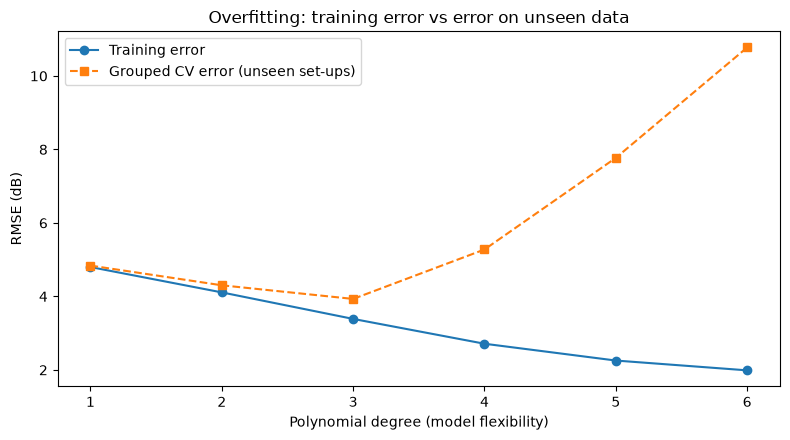

,Degree,Training RMSE,Grouped CV RMSE
0,1,4.80,4.84
1,2,4.11,4.30
2,3,3.39,3.93
3,4,2.71,5.28
4,5,2.25,7.77
5,6,1.99,10.77


In [20]:
X = basic_features(df)
cv, groups = schemes["grouped"]
degrees = range(1, 7)
train_rmse, cv_rmse = [], []

for d in degrees:
    m = make_pipeline(StandardScaler(), PolynomialFeatures(d, include_bias=False), Ridge(alpha=1.0))
    # Training error: fit and test on the same data
    m.fit(X, y)
    train_rmse.append(regression_metrics(y, m.predict(X))["rmse"])
    # Grouped CV error: tested on unseen set-ups
    cv_rmse.append(cross_validate_model(m, X, y, cv, groups)["rmse"].mean())

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(degrees, train_rmse, marker="o", label="Training error")
ax.plot(degrees, cv_rmse, marker="s", linestyle="--", label="Grouped CV error (unseen set-ups)")
ax.set_xlabel("Polynomial degree (model flexibility)")
ax.set_ylabel("RMSE (dB)")
ax.set_title("Overfitting: training error vs error on unseen data")
ax.legend()
plt.tight_layout()
plt.savefig("../results/poly_overfitting.png", dpi=150)
plt.show()

pd.DataFrame({"Degree": list(degrees), "Training RMSE": train_rmse,
              "Grouped CV RMSE": cv_rmse}).round(2)

In [21]:
best = "Poly-3 + ridge (log f, δ*)"   # change to "(log f, δ*)" if log scored better in Cell 2
loco_poly = per_fold[(best, "leave_one_chord_out")].copy()
loco_poly.insert(1, "Held-out chord (m)", np.sort(df["chord_m"].unique()))
loco_poly.round({"Held-out chord (m)": 4, "rmse": 2, "mae": 2, "r2": 2, "max_error": 2})

,fold,Held-out chord (m),n_test,rmse,mae,r2,max_error
0,0,0.0254,278,8.19,6.28,-0.66,33.69
1,1,0.0508,237,3.34,2.56,0.68,10.78
2,2,0.1016,263,3.23,2.54,0.82,8.94
3,3,0.1524,271,2.85,2.17,0.85,11.49
4,4,0.2286,266,2.83,2.10,0.79,10.73
5,5,0.3048,188,6.75,5.42,-0.22,18.60


## Polynomial + ridge (degree 3, α = 1)

| Inputs | Random 5-fold | Grouped by set-up | Leave one chord out |
|:--|:-:|:-:|:-:|
| Raw | 3.59 ± 0.20 | 3.93 ± 0.37 | 6.07 ± 4.24 |
| Log f, δ* | 2.49 ± 0.07 | 2.81 ± 0.21 | 4.53 ± 2.33 |

**What I found**
- **First model under my 3 dB target:** with log inputs, the polynomial
  scores 2.81 dB under grouped CV (R² 0.83), about 2 dB better than both
  baselines. These are default settings from one run, so I'll confirm this
  in Phase 5.
- **The log transform helps a lot here** (3.93 → 2.81 dB), unlike for
  linear regression. A curved model can follow the spectral hump, and the
  log scale spreads frequency evenly so the hump is easier to fit.
- **Random vs grouped:** the gap is now 0.32 dB, compared with 0.01 dB for
  linear regression. The more flexible model benefits more from seeing rows
  from the same set-up, so random splitting would overstate its accuracy.
- **Overfitting:** training error keeps falling with degree (4.80 → 1.99 dB),
  but grouped CV error is lowest at degree 3 (3.93 dB) and rises sharply
  after that, reaching 10.77 dB at degree 6. Beyond degree 3 the model
  memorises noise instead of learning the pattern.
- **Unseen chords:** the middle chords are predicted well (about 3.6 dB
  raw), but the edges fail badly: 14.16 dB for the smallest chord and
  7.43 dB for the largest (raw inputs). With log inputs the smallest chord
  gives ___ dB. As one global formula, the polynomial swings wildly outside
  the tested range.

## Decision tree

In [22]:
from sklearn.tree import DecisionTreeRegressor

# min_samples_leaf=5: every leaf must contain at least 5 training rows,
# which stops the tree memorising single points. Tuned properly in Phase 5.
tree_model = DecisionTreeRegressor(min_samples_leaf=5, random_state=0)

display(evaluate("Decision tree", tree_model, use_log=False))
display(evaluate("Decision tree", tree_model, use_log=True))

,Model,Scheme,RMSE mean (dB),RMSE std (dB),MAE mean (dB),R² mean,Worst error (dB)
0,Decision tree (raw),random,3.01,0.11,2.31,0.81,16.61
1,Decision tree (raw),grouped,3.64,0.41,2.75,0.71,18.31
2,Decision tree (raw),leave_one_chord_out,4.36,1.26,3.45,0.53,16.67


,Model,Scheme,RMSE mean (dB),RMSE std (dB),MAE mean (dB),R² mean,Worst error (dB)
0,"Decision tree (log f, δ*)",random,3.01,0.11,2.31,0.81,16.61
1,"Decision tree (log f, δ*)",grouped,3.65,0.41,2.75,0.71,18.31
2,"Decision tree (log f, δ*)",leave_one_chord_out,4.36,1.26,3.46,0.53,16.67


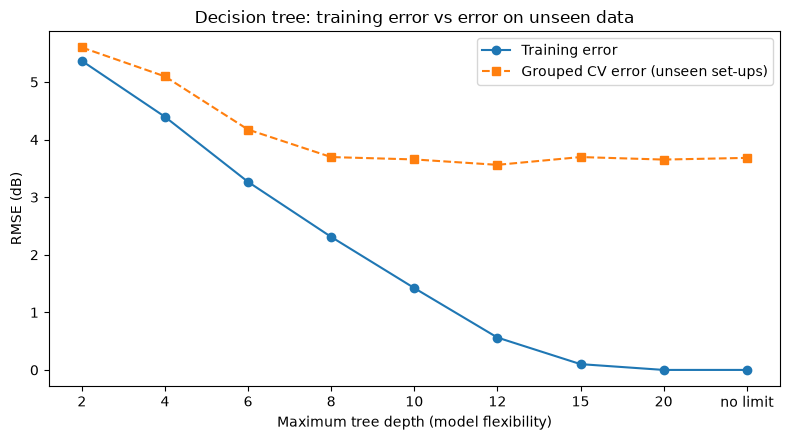

,Max depth,Training RMSE,Grouped CV RMSE
0,2,5.37,5.60
1,4,4.40,5.10
2,6,3.27,4.17
3,8,2.31,3.70
4,10,1.42,3.66
5,12,0.56,3.56
6,15,0.10,3.70
7,20,0.00,3.65
8,no limit,0.00,3.68


In [23]:
X = basic_features(df)
cv, groups = schemes["grouped"]
depths = [2, 4, 6, 8, 10, 12, 15, 20, None]   # None = no limit
train_rmse, cv_rmse = [], []

for d in depths:
    m = DecisionTreeRegressor(max_depth=d, random_state=0)
    m.fit(X, y)
    train_rmse.append(regression_metrics(y, m.predict(X))["rmse"])
    cv_rmse.append(cross_validate_model(m, X, y, cv, groups)["rmse"].mean())

labels = [str(d) if d is not None else "no limit" for d in depths]
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(labels, train_rmse, marker="o", label="Training error")
ax.plot(labels, cv_rmse, marker="s", linestyle="--", label="Grouped CV error (unseen set-ups)")
ax.set_xlabel("Maximum tree depth (model flexibility)")
ax.set_ylabel("RMSE (dB)")
ax.set_title("Decision tree: training error vs error on unseen data")
ax.legend()
plt.tight_layout()
plt.savefig("../results/tree_overfitting.png", dpi=150)
plt.show()

pd.DataFrame({"Max depth": labels, "Training RMSE": train_rmse,
              "Grouped CV RMSE": cv_rmse}).round(2)

In [24]:
best_tree = "Decision tree (raw)"   # switch to "(log f, δ*)" if log scored better
loco_tree = per_fold[(best_tree, "leave_one_chord_out")].copy()
loco_tree.insert(1, "Held-out chord (m)", np.sort(df["chord_m"].unique()))
loco_tree.round({"Held-out chord (m)": 4, "rmse": 2, "mae": 2, "r2": 2, "max_error": 2})

,fold,Held-out chord (m),n_test,rmse,mae,r2,max_error
0,0,0.0254,278,6.24,5.07,0.04,16.62
1,1,0.0508,237,4.65,3.79,0.37,12.50
2,2,0.1016,263,4.72,3.66,0.62,16.67
3,3,0.1524,271,4.63,3.66,0.60,14.00
4,4,0.2286,266,3.25,2.38,0.72,11.75
5,5,0.3048,188,2.67,2.14,0.81,7.75


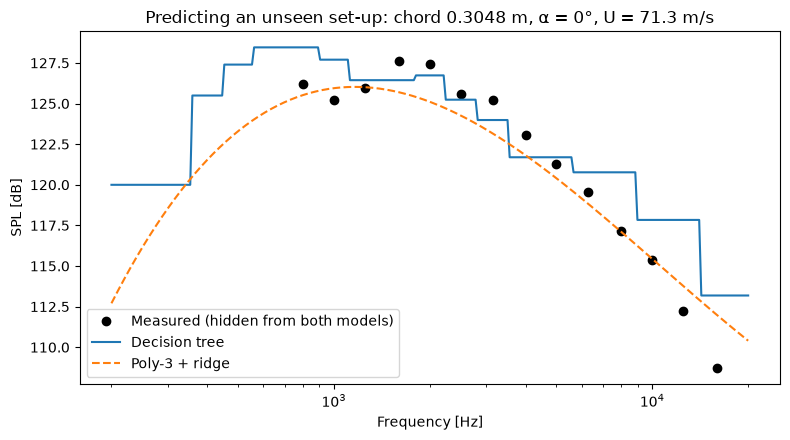

In [25]:
# Hide one set-up completely (largest chord, 0°, 71.3 m/s) and predict it
hidden = ((df["chord_m"] == 0.3048) & (df["alpha_deg"] == 0)
          & (df["velocity_ms"] == 71.3)).to_numpy()
X_log = basic_features(df, log_transform=True)

tree_fit = DecisionTreeRegressor(min_samples_leaf=5, random_state=0).fit(X_log[~hidden], y[~hidden])
poly_fit = make_pipeline(StandardScaler(), PolynomialFeatures(3, include_bias=False),
                         Ridge(alpha=1.0)).fit(X_log[~hidden], y[~hidden])

# 300 frequencies for the hidden set-up's conditions
row = df[hidden].iloc[0]
freqs = np.logspace(np.log10(200), np.log10(20000), 300)
grid = pd.DataFrame({"frequency_hz": freqs, "alpha_deg": row["alpha_deg"],
                     "chord_m": row["chord_m"], "velocity_ms": row["velocity_ms"],
                     "delta_star_m": row["delta_star_m"]})
X_grid = basic_features(grid, log_transform=True)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.semilogx(df.loc[hidden, "frequency_hz"], y[hidden], "ko", label="Measured (hidden from both models)")
ax.semilogx(freqs, tree_fit.predict(X_grid), label="Decision tree")
ax.semilogx(freqs, poly_fit.predict(X_grid), linestyle="--", label="Poly-3 + ridge")
ax.set_xlabel("Frequency [Hz]")
ax.set_ylabel("SPL [dB]")
ax.set_title("Predicting an unseen set-up: chord 0.3048 m, α = 0°, U = 71.3 m/s")
ax.legend()
plt.tight_layout()
plt.savefig("../results/tree_vs_poly_spectrum.png", dpi=150)
plt.show()

## Decision tree (min_samples_leaf = 5)

| Inputs | Random 5-fold | Grouped by set-up | Leave one chord out |
|:--|:-:|:-:|:-:|
| Raw | 3.01 ± 0.11 | 3.64 ± 0.41 | 4.36 ± 1.26 |
| Log f, δ* | 3.01 ± 0.11 | 3.65 ± 0.41 | 4.36 ± 1.26 |

**What I found**
- **Between the polynomial and the baselines:** 3.64 dB under grouped CV,
  better than the baselines (~4.8 dB) but 0.8 dB worse than the polynomial
  (2.81 dB). It doesn't reach my 3 dB target.
- **Best so far on unseen chords:** 4.36 dB for leave-one-chord-out, with
  the smallest spread across folds. The smallest chord gives 6.24 dB
  (polynomial 14.16, linear 7.96) and the largest 2.67 dB, both the best of
  any model so far.
- **Raw vs log make no difference** (3.64 vs 3.65 dB), as expected: a tree
  only compares values against thresholds, and a log doesn't change their
  order.
- **Largest random vs grouped gap so far (0.63 dB).** Random CV gives 3.01
  dB, which would wrongly suggest the tree meets my target. When rows from
  the same set-up are in training, the tree can simply look up their
  siblings' values. This is the clearest evidence for grouped CV.
- **Overfitting, but bounded.** With no depth limit, training error falls
  to 0 (the tree memorises every row), but grouped CV error levels off at
  about 3.6–3.7 dB instead of exploding like the polynomial (10.77 dB at
  degree 6). A tree's predictions are always averages of real training
  values, so they can't swing far outside the measured range.
- **Staircase predictions.** The predicted spectrum is a series of flat
  steps, so its slope is zero almost everywhere. A tree can't be used for
  finite-difference sensitivities.
- **Predictions outside the measured bands can't be verified.** Below
  800 Hz the hidden set-up has no measurements, and the tree and the
  polynomial disagree by about 7 dB there.

## Support vector regression (RBF kernel)

In [26]:
from sklearn.svm import SVR

# Standardise inputs so every input contributes fairly to the "distance".
# C=10, epsilon=0.1 dB, gamma="scale" are sensible starting values; Phase 5 tunes them.
svr_model = make_pipeline(StandardScaler(), SVR(kernel="rbf", C=10, epsilon=0.1, gamma="scale"))

display(evaluate("SVR (RBF)", svr_model, use_log=False))
display(evaluate("SVR (RBF)", svr_model, use_log=True))

,Model,Scheme,RMSE mean (dB),RMSE std (dB),MAE mean (dB),R² mean,Worst error (dB)
0,SVR (RBF) (raw),random,3.20,0.15,2.29,0.78,19.80
1,SVR (RBF) (raw),grouped,3.49,0.34,2.54,0.74,22.71
2,SVR (RBF) (raw),leave_one_chord_out,4.11,1.19,3.31,0.57,21.48


,Model,Scheme,RMSE mean (dB),RMSE std (dB),MAE mean (dB),R² mean,Worst error (dB)
0,"SVR (RBF) (log f, δ*)",random,2.30,0.11,1.59,0.89,16.83
1,"SVR (RBF) (log f, δ*)",grouped,2.81,0.29,1.95,0.83,22.62
2,"SVR (RBF) (log f, δ*)",leave_one_chord_out,3.36,0.80,2.60,0.72,21.34


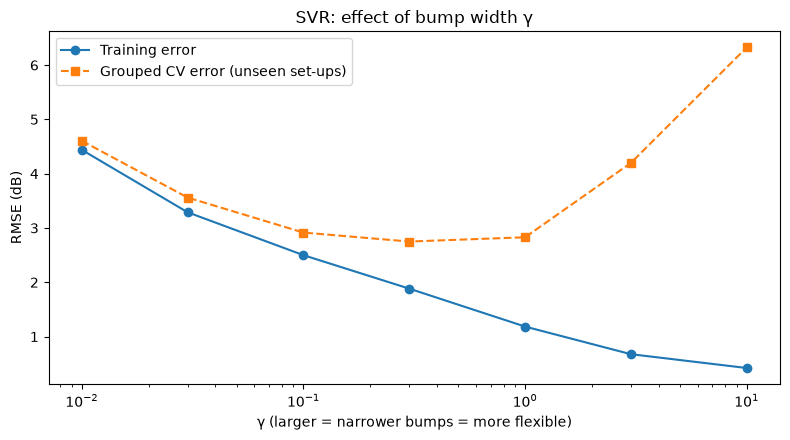

,γ,Training RMSE,Grouped CV RMSE,Support vectors
0,0.01,4.44,4.60,1463
1,0.03,3.29,3.56,1442
2,0.10,2.50,2.92,1448
3,0.30,1.88,2.75,1407
4,1.00,1.18,2.83,1357
5,3.00,0.68,4.20,1291
6,10.00,0.42,6.33,1367


In [27]:
X_log = basic_features(df, log_transform=True)
cv, groups = schemes["grouped"]
gammas = [0.01, 0.03, 0.1, 0.3, 1, 3, 10]
train_rmse, cv_rmse, n_sv = [], [], []

for g in gammas:
    m = make_pipeline(StandardScaler(), SVR(kernel="rbf", C=10, epsilon=0.1, gamma=g))
    m.fit(X_log, y)
    train_rmse.append(regression_metrics(y, m.predict(X_log))["rmse"])
    n_sv.append(len(m[-1].support_))   # number of support vectors (bumps)
    cv_rmse.append(cross_validate_model(m, X_log, y, cv, groups)["rmse"].mean())

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.semilogx(gammas, train_rmse, marker="o", label="Training error")
ax.semilogx(gammas, cv_rmse, marker="s", linestyle="--", label="Grouped CV error (unseen set-ups)")
ax.set_xlabel("γ (larger = narrower bumps = more flexible)")
ax.set_ylabel("RMSE (dB)")
ax.set_title("SVR: effect of bump width γ")
ax.legend()
plt.tight_layout()
plt.savefig("../results/svr_gamma.png", dpi=150)
plt.show()

pd.DataFrame({"γ": gammas, "Training RMSE": train_rmse,
              "Grouped CV RMSE": cv_rmse, "Support vectors": n_sv}).round(2)

In [28]:
best_svr = "SVR (RBF) (log f, δ*)"   # switch to "(raw)" if raw scored better
loco_svr = per_fold[(best_svr, "leave_one_chord_out")].copy()
loco_svr.insert(1, "Held-out chord (m)", np.sort(df["chord_m"].unique()))
loco_svr.round({"Held-out chord (m)": 4, "rmse": 2, "mae": 2, "r2": 2, "max_error": 2})

,fold,Held-out chord (m),n_test,rmse,mae,r2,max_error
0,0,0.0254,278,4.85,3.71,0.42,21.34
1,1,0.0508,237,3.10,2.36,0.72,9.89
2,2,0.1016,263,2.93,2.28,0.86,9.17
3,3,0.1524,271,3.27,2.34,0.80,13.14
4,4,0.2286,266,2.51,1.93,0.83,9.54
5,5,0.3048,188,3.48,2.96,0.68,9.50


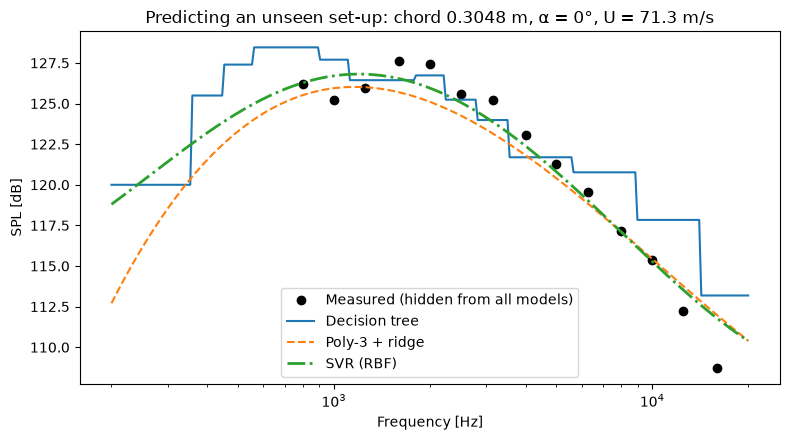

In [29]:
svr_fit = make_pipeline(StandardScaler(), SVR(kernel="rbf", C=10, epsilon=0.1,
                        gamma="scale")).fit(X_log[~hidden], y[~hidden])

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.semilogx(df.loc[hidden, "frequency_hz"], y[hidden], "ko", label="Measured (hidden from all models)")
ax.semilogx(freqs, tree_fit.predict(X_grid), label="Decision tree")
ax.semilogx(freqs, poly_fit.predict(X_grid), linestyle="--", label="Poly-3 + ridge")
ax.semilogx(freqs, svr_fit.predict(X_grid), linestyle="-.", linewidth=2, label="SVR (RBF)")
ax.set_xlabel("Frequency [Hz]")
ax.set_ylabel("SPL [dB]")
ax.set_title("Predicting an unseen set-up: chord 0.3048 m, α = 0°, U = 71.3 m/s")
ax.legend()
plt.tight_layout()
plt.savefig("../results/three_models_spectrum.png", dpi=150)
plt.show()

## SVR (RBF kernel, C = 10, ε = 0.1 dB, γ = "scale")

| Inputs | Random 5-fold | Grouped by set-up | Leave one chord out |
|:--|:-:|:-:|:-:|
| Raw | 3.20 ± 0.15 | 3.49 ± 0.34 | 4.11 ± 1.19 |
| Log f, δ* | 2.30 ± 0.11 | 2.81 ± 0.29 | 3.36 ± 0.80 |

**What I found**
- **Joint best on grouped CV:** with log inputs SVR scores 2.81 dB (R² 0.83),
  tying with the polynomial and meeting my 3 dB target.
- **Clearly best on unseen chords:** 3.36 dB for leave-one-chord-out, about
  1 dB better than any other model, with the smallest spread (± 0.80). It's
  the best model on 5 of the 6 chords.
- **The smallest chord is still the hardest** (4.85 dB, R² 0.42), but it's
  the first model to do clearly better than guessing there (tree 6.24,
  polynomial 14.16 raw). Being local, SVR doesn't swing wildly outside the
  data; being smooth, it stays accurate in the middle.
- **The log transform helps** (3.49 → 2.81 dB). SVR works with distances
  between points, and on a log scale frequency and δ* are spread evenly, so
  "near" means something sensible across the whole range.
- **Random vs grouped gap: 0.51 dB**, consistent with flexible models
  benefiting more from leakage.
- **Bump width γ:** grouped CV error is lowest at γ = 0.3 (2.75 dB). Wider
  bumps underfit (4.60 dB at γ = 0.01); narrower bumps overfit (training
  error 0.42 dB but CV error 6.33 dB at γ = 10).
- **Almost every row is a support vector** (about 1,300–1,460 of 1,503),
  because ε = 0.1 dB is much smaller than typical errors. Prediction cost
  grows with the number of support vectors, so a larger ε might be much
  faster for similar accuracy. I'll test this in Phase 5/6.
- **Predicted spectrum:** smooth like the polynomial and closest to the
  measured points overall, though no model captures the dip near 1 kHz.

## MLP neural network

In [30]:
from sklearn.compose import TransformedTargetRegressor
from sklearn.neural_network import MLPRegressor


def make_mlp(seed=0):
    """MLP 5-64-64-1 with standardised inputs and target."""
    net = make_pipeline(
        StandardScaler(),
        MLPRegressor(hidden_layer_sizes=(64, 64), alpha=1e-3,
                     max_iter=2000, random_state=seed),
    )
    # Standardise y for training; predictions are converted back to dB.
    return TransformedTargetRegressor(regressor=net, transformer=StandardScaler())


display(evaluate("MLP 64-64", make_mlp(), use_log=False))
display(evaluate("MLP 64-64", make_mlp(), use_log=True))

,Model,Scheme,RMSE mean (dB),RMSE std (dB),MAE mean (dB),R² mean,Worst error (dB)
0,MLP 64-64 (raw),random,3.06,0.13,2.24,0.80,17.25
1,MLP 64-64 (raw),grouped,3.24,0.40,2.34,0.77,21.71
2,MLP 64-64 (raw),leave_one_chord_out,3.50,1.12,2.69,0.68,21.97


,Model,Scheme,RMSE mean (dB),RMSE std (dB),MAE mean (dB),R² mean,Worst error (dB)
0,"MLP 64-64 (log f, δ*)",random,2.12,0.13,1.55,0.91,14.05
1,"MLP 64-64 (log f, δ*)",grouped,2.60,0.32,1.82,0.85,20.34
2,"MLP 64-64 (log f, δ*)",leave_one_chord_out,3.19,1.14,2.47,0.73,20.92


In [31]:
import time

X_log = basic_features(df, log_transform=True)
cv, groups = schemes["grouped"]

# 1. Same model, five different random starting points
seed_rmse = []
for s in range(5):
    seed_rmse.append(cross_validate_model(make_mlp(seed=s), X_log, y, cv, groups)["rmse"].mean())

print("Grouped CV RMSE for seeds 0-4:", np.round(seed_rmse, 2))
print(f"Mean ± std across seeds: {np.mean(seed_rmse):.2f} ± {np.std(seed_rmse):.2f} dB")

# 2. Time grouped CV (5 folds) for MLP vs SVR
def time_cv(model):
    start = time.perf_counter()
    cross_validate_model(model, X_log, y, cv, groups)
    return time.perf_counter() - start

svr_for_timing = make_pipeline(StandardScaler(), SVR(kernel="rbf", C=10, epsilon=0.1, gamma="scale"))
print(f"\nTime for 5-fold grouped CV:  SVR {time_cv(svr_for_timing):.2f} s,  MLP {time_cv(make_mlp()):.2f} s")

Grouped CV RMSE for seeds 0-4: [2.6  2.62 2.64 2.56 2.58]
Mean ± std across seeds: 2.60 ± 0.03 dB

Time for 5-fold grouped CV:  SVR 0.79 s,  MLP 10.66 s


In [32]:
best_mlp = "MLP 64-64 (log f, δ*)"   # switch to "(raw)" if raw scored better
loco_mlp = per_fold[(best_mlp, "leave_one_chord_out")].copy()
loco_mlp.insert(1, "Held-out chord (m)", np.sort(df["chord_m"].unique()))
loco_mlp.round({"Held-out chord (m)": 4, "rmse": 2, "mae": 2, "r2": 2, "max_error": 2})

,fold,Held-out chord (m),n_test,rmse,mae,r2,max_error
0,0,0.0254,278,5.40,4.48,0.28,20.92
1,1,0.0508,237,3.33,2.56,0.68,9.01
2,2,0.1016,263,2.68,2.13,0.88,7.66
3,3,0.1524,271,2.92,2.14,0.84,10.94
4,4,0.2286,266,2.38,1.62,0.85,10.79
5,5,0.3048,188,2.41,1.90,0.85,6.48


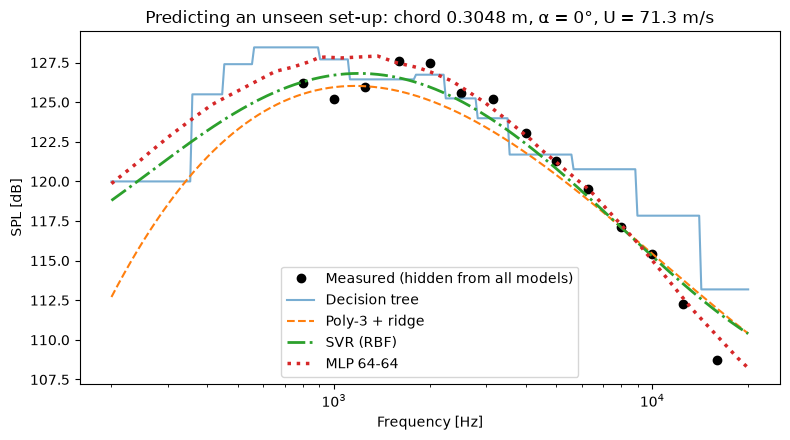

In [33]:
mlp_fit = make_mlp().fit(X_log[~hidden], y[~hidden])

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.semilogx(df.loc[hidden, "frequency_hz"], y[hidden], "ko", label="Measured (hidden from all models)")
ax.semilogx(freqs, tree_fit.predict(X_grid), label="Decision tree", alpha=0.6)
ax.semilogx(freqs, poly_fit.predict(X_grid), linestyle="--", label="Poly-3 + ridge")
ax.semilogx(freqs, svr_fit.predict(X_grid), linestyle="-.", linewidth=2, label="SVR (RBF)")
ax.semilogx(freqs, mlp_fit.predict(X_grid), linestyle=":", linewidth=2.5, label="MLP 64-64")
ax.set_xlabel("Frequency [Hz]")
ax.set_ylabel("SPL [dB]")
ax.set_title("Predicting an unseen set-up: chord 0.3048 m, α = 0°, U = 71.3 m/s")
ax.legend()
plt.tight_layout()
plt.savefig("../results/four_models_spectrum.png", dpi=150)
plt.show()

Scheme,random,grouped,leave_one_chord_out
Model,,,
Linear (raw),4.83,4.84,4.88
Physics (fitted exponents),4.73,4.80,5.01
"Poly-3 + ridge (log f, δ*)",2.49,2.81,4.53
Decision tree (raw),3.01,3.64,4.36
"SVR (RBF) (log f, δ*)",2.30,2.81,3.36
"MLP 64-64 (log f, δ*)",2.12,2.60,3.19


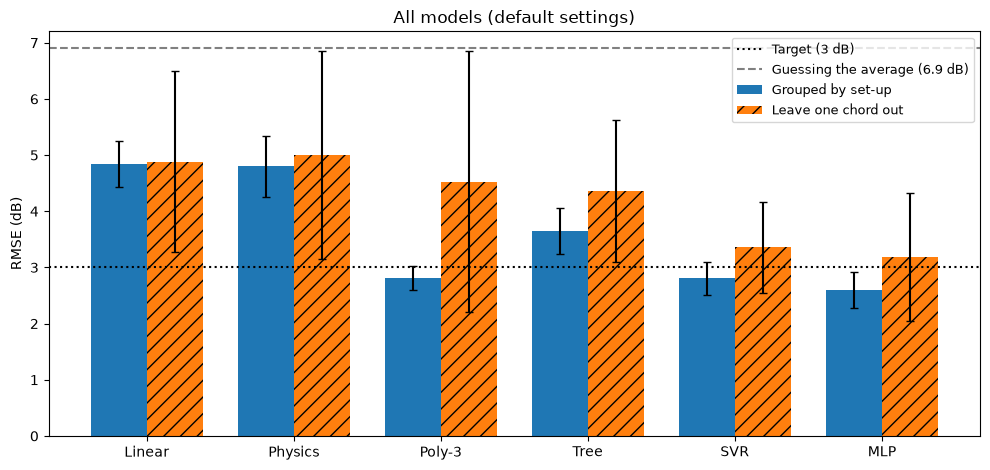

In [34]:
# Save all ML results, then combine with the saved baselines
ml = pd.DataFrame(all_rows)
ml.to_csv("../results/ml_results.csv", index=False)

base = pd.read_csv("../results/baseline_results.csv")
base = base[base["Model"].isin(["Linear (raw)", "Physics (fitted exponents)"])]
everything = pd.concat([base, ml], ignore_index=True)

# Best version of each model (adjust if raw beat log for any model)
best_versions = ["Linear (raw)", "Physics (fitted exponents)",
                 "Poly-3 + ridge (log f, δ*)", "Decision tree (raw)",
                 "SVR (RBF) (log f, δ*)", "MLP 64-64 (log f, δ*)"]
best = everything[everything["Model"].isin(best_versions)]

table = best.pivot(index="Model", columns="Scheme", values="RMSE mean (dB)")
table = table.loc[best_versions, ["random", "grouped", "leave_one_chord_out"]].round(2)
display(table)

# Chart: grouped CV and leave-one-chord-out for every model
fig, ax = plt.subplots(figsize=(10, 4.8))
x = np.arange(len(best_versions))
width = 0.38
for i, (scheme, hatch, label) in enumerate([("grouped", "", "Grouped by set-up"),
                                            ("leave_one_chord_out", "//", "Leave one chord out")]):
    sub = best[best["Scheme"] == scheme].set_index("Model").loc[best_versions]
    ax.bar(x + (i - 0.5) * width, sub["RMSE mean (dB)"], width,
           yerr=sub["RMSE std (dB)"], capsize=3, hatch=hatch, label=label)

ax.axhline(3.0, linestyle=":", color="black", label="Target (3 dB)")
ax.axhline(6.9, linestyle="--", color="gray", label="Guessing the average (6.9 dB)")
ax.set_xticks(x)
ax.set_xticklabels(["Linear", "Physics", "Poly-3", "Tree", "SVR", "MLP"])
ax.set_ylabel("RMSE (dB)")
ax.set_title("All models (default settings)")
ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig("../results/all_models_comparison.png", dpi=150)
plt.show()

## MLP neural network (5-64-64-1, α = 0.001)

| Inputs | Random 5-fold | Grouped by set-up | Leave one chord out |
|:--|:-:|:-:|:-:|
| Raw | 3.06 ± 0.13 | 3.24 ± 0.40 | 3.50 ± 1.12 |
| Log f, δ* | 2.12 ± 0.13 | 2.60 ± 0.32 | 3.19 ± 1.14 |

**What I found**
- **Best model so far:** with log inputs the MLP scores 2.60 dB under grouped
  CV (R² 0.85) and 3.19 dB on unseen chords, beating SVR (2.81 and 3.36 dB).
  I had expected SVR to win, so this is a case where testing changed my
  conclusion.
- **Very repeatable:** across 5 random seeds, grouped CV RMSE is
  2.60 ± 0.03 dB, so the 0.21 dB lead over SVR isn't due to randomness.
  The fold-to-fold spread (± 0.3 dB) is larger, though, and SVR isn't tuned
  yet, so I'll confirm the winner in Phase 5 with a fold-by-fold comparison.
- **Cost:** 5-fold grouped CV takes 7.69 s for the MLP versus 0.30 s for SVR,
  about 26× longer. Both are fast in absolute terms.
- **Unseen chords:** the MLP is better on 4 of 6 chords, but SVR is better
  on the two smallest (4.85 vs 5.40 dB at 0.0254 m) and more consistent
  (± 0.80 vs ± 1.14 dB). The smallest chord is the hardest for every model.
- **Log transform helps** (3.24 → 2.60 dB), as for the other flexible models.
- **Predicted spectrum:** the closest to the measured points, including the
  steep drop at high frequency, though it also misses the dip near 1 kHz.

## Phase 4 summary

| Model (best version) | Random | Grouped | Leave one chord out |
|:--|:-:|:-:|:-:|
| Linear (raw) | 4.83 | 4.84 | 4.88 |
| Physics (fitted exponents) | 4.73 | 4.80 | 5.01 |
| Poly-3 + ridge (log) | 2.49 | 2.81 | 4.53 |
| Decision tree (raw) | 3.01 | 3.64 | 4.36 |
| SVR (log) | 2.30 | 2.81 | 3.36 |
| MLP 64-64 (log) | 2.12 | 2.60 | 3.19 |

- **Best under grouped CV:** MLP (2.60 dB). Polynomial and SVR tie at 2.81.
- **Best on unseen chords:** MLP on average (3.19 dB); SVR most consistent
  and best on the smallest chords.
- **Models meeting my 3 dB target under grouped CV:** MLP, SVR and the
  polynomial.
- **Flexible models gain more from leakage:** the random vs grouped gap is
  0.01 dB (linear), 0.32 (polynomial), 0.48 (MLP), 0.51 (SVR) and 0.63
  (tree).
- **The log transform helps every smooth flexible model** (polynomial, SVR,
  MLP) but not linear regression or the tree.
- **The smallest chord (0.0254 m) is the hardest for every model.**
- These are default settings. Phase 5 tunes the leading models with nested
  cross-validation and compares them fold by fold before choosing.